<a href="https://colab.research.google.com/github/krueg-lars-web/DataSciene/blob/main/colab/exercise_05/kmeans-clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# k-means Clustering

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Clustering

> <font color="#e8710a">**📝 Tasks**</font>
>
> 1. Is clustering a supervised or an unsupervised learning problem?
> 2. Improve the points in the `centroids` variable below, such that the clusters visually look like they capture the data better to you! Give it just one shot, no need for perfection.

**✏️ Your answer**

1. unüberwacht

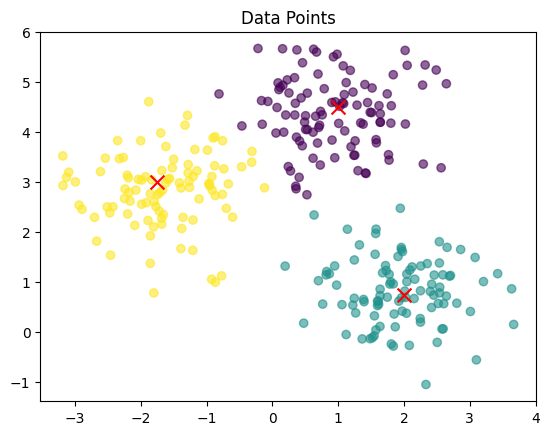

In [7]:
from sklearn.datasets import make_blobs

X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.7, random_state=0)

centroids = np.array([  # TODO: 2. these points seem a little off. Can you improve them?
    [1, 4.5],
    [2, 0.75],
    [-1.75, 3]
])
labels = np.argmin(((X_blobs[:, None, :] - centroids[None, :, :])**2).sum(axis=2), axis=1)

plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, cmap='viridis', alpha=0.6)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='x', s=100)
plt.title("Data Points")
plt.show()

## Optimization Target

Let's have a look at whether your new cluster definition is better that the one given. For that, we will have to define what makes a good clustering.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 3. Implement the target function from the lecture in `clustering_cost`!

In [8]:
def clustering_cost(X, centroids, labels):
    cost = 0

    for j in range(len(X)):
        distance = np.sum((X[j] - centroids[labels[j]])**2)
        cost += distance

    return cost

# Given centroids from the previous task
centroids_1 = np.array([[-1.5, 4], [1.5, 2], [-1.5, 2]])
labels_1 = np.argmin(((X_blobs[:, None, :] - centroids_1[None, :, :])**2).sum(axis=2), axis=1)

cost_1 = clustering_cost(X_blobs, centroids_1, labels_1)
print(f"Cost of given centroids: {cost_1:.2f}")
cost = clustering_cost(X_blobs, centroids, labels)
print(f"Cost of improved centroids: {cost:.2f}")

Cost of given centroids: 841.33
Cost of improved centroids: 293.50


> <font color="#e8710a">**📝 Tasks**</font>
>
> 4. The defined points are called `centroids` in the code, but that is not correct. Why are they not actual centroids?

**✏️ Your answer**

4. Weil wir uns Visuell irgendwelche Werte ausgesucht haben aber nicht die Mathematischen Mittelwerte der jeweiligen Cluster gebildet haben

## Lloyd's Algorithm

> <font color="#e8710a">**📝 Tasks**</font>
>
> 5. How are the clusters initialized in the following implementation of k-means? Was it the same in the lecture?
> 6. Look up the k-means documentation of sklearn. What other options are there for initialization?
> 7. Complete the following implementation of the k-means clustering algorithm from the lecture! You just need to add a single function call for each of the question marks.

**✏️ Your answer**

5.
6.

In [ ]:
def kmeans(X, k=3, n_iter=10):
    centroids = X[np.random.choice(len(X), k, replace=False)]

    for _ in range(n_iter):
        labels = ?(((X[:, None, :] - centroids[None, :, :])**2).sum(axis=2), axis=1)  # TODO: 7. complete (insert a function) at the question mark
        centroids = np.array([X[labels == j].? for j in range(k)])  # TODO: 7. complete (insert a function) at the question mark

    return centroids, labels

centroids, labels = kmeans(X_blobs, k=3, n_iter=10)
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, cmap='viridis', alpha=0.6)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='x', s=100)
plt.title("k-Means Result")
plt.show()